# 00 · Cómo funciona el item-kNN

El modelo principal del proyecto recomienda con la idea de que *a la gente que le gustó X
también le gustó Y*. Este notebook lo enseña en dos partes:

1. Un ejemplo de muestra con tres usuarios, que se puede comprobar a mano.
2. El modelo con los datos reales de Gold: los juegos más parecidos a uno conocido, y una
   recomendación para una colección inventada, explicada juego a juego.

El código es el de la librería (`siguiente_partida.recomendadores`): lo que se ve aquí es
exactamente lo que se evalúa en `ml/evaluar.py`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from scipy import sparse

from siguiente_partida.recomendadores import ItemKNN, Popularidad

## 1. Ejemplo de muestra

Tres usuarios y tres juegos. Un 1 significa que el usuario ha valorado el juego
(variante binaria: solo importa *si* lo valoró).

|  | Juego A | Juego B | Juego C |
|---|---|---|---|
| Ana | 1 | 1 | 0 |
| Berto | 1 | 1 | 1 |
| Carla | 1 | 0 | 0 |

In [2]:
juegos_ej = ["Juego A", "Juego B", "Juego C"]
R_ej = sparse.csr_matrix(np.array([[1, 1, 0],
                                   [1, 1, 1],
                                   [1, 0, 0]], dtype=np.float32))

**Paso 1: similitud entre juegos.** Dos juegos se parecen si los ha valorado la misma gente.
Se usa el coseno:

$$\text{similitud}(i, j) = \frac{\text{usuarios que valoraron los dos}}{\sqrt{\text{usuarios de } i} \cdot \sqrt{\text{usuarios de } j}}$$

Dividir por el tamaño de cada grupo evita que un juego muy popular salga parecido a todo.

- A y B: 2 usuarios en común, A tiene 3 y B tiene 2 → 2 / √(3·2) ≈ 0,82
- A y C: 1 en común, A tiene 3 y C tiene 1 → 1 / √(3·1) ≈ 0,58
- B y C: 1 en común, B tiene 2 y C tiene 1 → 1 / √(2·1) ≈ 0,71

In [3]:
modelo_ej = ItemKNN(vecinos=2, variante="binaria").ajustar(R_ej)
pd.DataFrame(modelo_ej.matriz_vecinos().toarray(), index=juegos_ej, columns=juegos_ej).round(2)

,Juego A,Juego B,Juego C
Juego A,0.00,0.82,0.58
Juego B,0.82,0.00,0.71
Juego C,0.58,0.71,0.00


**Paso 2: puntuar para un usuario.** Carla solo tiene el juego A. La puntuación de cada
juego que no tiene es la suma de sus similitudes con los juegos que sí tiene:
B saca 0,82 y C saca 0,58. Se le recomienda **B**.

In [4]:
carla = R_ej[2]
puntos = modelo_ej.puntuar(carla)[0]
print(pd.Series(puntos, index=juegos_ej).round(2).to_string())
top, _ = modelo_ej.recomendar(carla, k=1)
print("\nRecomendación para Carla:", juegos_ej[top[0, 0]])

Juego A    0.00
Juego B    0.82
Juego C    0.58

Recomendación para Carla: Juego B


Las dos variantes que se comparan en el proyecto:

- **Binaria:** solo importa haber valorado el juego (lo de arriba).
- **Centrada:** se usa la nota menos la media del usuario. Lo que puntuó por debajo de su
  media *resta*: no basta con haberlo jugado, importa si le gustó.

## 2. Con los datos reales

Se entrena con **todas** las valoraciones de Gold, en la variante binaria y con 100 vecinos
por juego. Es solo para enseñar cómo funciona: la variante y el número de vecinos definitivos
salen de la validación (notebooks 01 y 02). Tarda menos de un minuto.

In [5]:
import pyarrow as pa
import pyarrow.csv as pv

GOLD = RAIZ / "data" / "gold"
v = pv.read_csv(GOLD / "valoracion.csv", convert_options=pv.ConvertOptions(
    column_types={"id_usuario": pa.int32(), "bgg_id": pa.int32(), "nota": pa.float32()}))
usuarios, fila = np.unique(v.column("id_usuario").to_numpy(), return_inverse=True)
bgg_ids, col = np.unique(v.column("bgg_id").to_numpy(), return_inverse=True)
R = sparse.csr_matrix((v.column("nota").to_numpy(), (fila, col)),
                      shape=(len(usuarios), len(bgg_ids)))
del v
nombres = (pv.read_csv(GOLD / "juego.csv",
                       parse_options=pv.ParseOptions(newlines_in_values=True),
                       convert_options=pv.ConvertOptions(include_columns=["bgg_id", "nombre"]))
           .to_pandas().set_index("bgg_id")["nombre"])
posicion = pd.Series(np.arange(len(bgg_ids)), index=bgg_ids)
n_valoraciones = np.diff(R.tocsc().indptr)
print(f"{R.nnz:,} valoraciones de {R.shape[0]:,} usuarios sobre {R.shape[1]:,} juegos".replace(",", "."))

18.340.325 valoraciones de 224.558 usuarios sobre 21.924 juegos


In [6]:
%%time
modelo = ItemKNN(vecinos=100, variante="binaria").ajustar(R)

CPU times: total: 19.3 s
Wall time: 19.8 s


### Los juegos más parecidos a uno conocido

Se busca *CATAN* (id 13 en BGG). Si no está (por ejemplo, con la muestra sintética),
se usa el juego con más valoraciones.

In [7]:
def juego(bgg_id):
    return f"{nombres.get(bgg_id, bgg_id)} ({bgg_id})"


def vecinos_de(bgg_id, n=10):
    i = posicion[bgg_id]
    return pd.DataFrame({
        "juego": [juego(bgg_ids[j]) for j in modelo.indices_[i, :n]],
        "similitud": modelo.similitudes_[i, :n].round(3),
        "valoraciones": n_valoraciones[modelo.indices_[i, :n]],
    }, index=range(1, n + 1))


ejemplo = 13 if 13 in posicion.index else int(bgg_ids[np.argmax(n_valoraciones)])
print("Juego de ejemplo:", juego(ejemplo), "-", n_valoraciones[posicion[ejemplo]], "valoraciones")
tabla_vecinos = vecinos_de(ejemplo)
tabla_vecinos

Juego de ejemplo: Catan (13) - 96428 valoraciones


,juego,similitud,valoraciones
1,Carcassonne (822),0.643,99560
2,Pandemic (30549),0.584,100103
3,Dominion (36218),0.571,76223
4,Ticket to Ride (9209),0.568,70890
5,7 Wonders (68448),0.561,84002
6,Puerto Rico (3076),0.537,60962
7,Power Grid (2651),0.515,55662
8,Small World (40692),0.514,61655
9,Agricola (31260),0.513,61600
10,Ticket to Ride: Europe (14996),0.486,59068


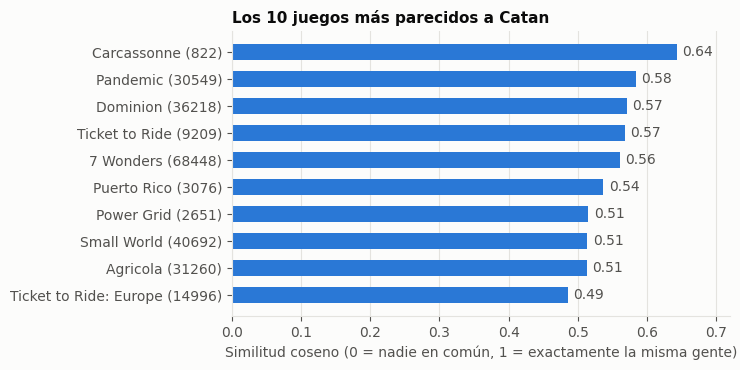

In [8]:
import matplotlib.pyplot as plt

AZUL, TEXTO, TEXTO_2, REJILLA, FONDO = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": FONDO, "axes.facecolor": FONDO, "axes.edgecolor": REJILLA,
                     "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
                     "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(tabla_vecinos))[::-1]
ax.barh(y, tabla_vecinos["similitud"], color=AZUL, height=0.6)
for yi, s in zip(y, tabla_vecinos["similitud"]):
    ax.annotate(f"{s:.2f}", (s, yi), xytext=(4, 0), textcoords="offset points",
                va="center", color=TEXTO_2)
ax.set_yticks(y)
ax.set_yticklabels(tabla_vecinos["juego"])
ax.set_xlabel("Similitud coseno (0 = nadie en común, 1 = exactamente la misma gente)")
ax.set_title(f"Los 10 juegos más parecidos a {nombres.get(ejemplo, ejemplo)}")
ax.grid(axis="x", color=REJILLA)
ax.set_axisbelow(True)
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

### Una recomendación explicada

Una colección inventada, como la que metería alguien en la app. El modelo no sabe quién es:
solo recibe sus juegos. Para cada juego recomendado se muestra **por qué**: el juego de la
colección que más aporta a su puntuación.

In [9]:
coleccion = [13, 822, 9209, 30549]   # CATAN, Carcassonne, Ticket to Ride, Pandemic
coleccion = [b for b in coleccion if b in posicion.index]
if len(coleccion) < 2:                # muestra sintética: los cuatro más valorados
    coleccion = [int(b) for b in bgg_ids[np.argsort(-n_valoraciones)[:4]]]
print("Colección:", ", ".join(juego(b) for b in coleccion))

usuario = sparse.csr_matrix((np.ones(len(coleccion), np.float32),
                             ([0] * len(coleccion), posicion[coleccion].to_numpy())),
                            shape=(1, len(bgg_ids)))
top, puntos = modelo.recomendar(usuario, k=10)

S = modelo.matriz_vecinos()
filas = []
for pos, (j, p) in enumerate(zip(top[0], puntos[0]), start=1):
    aporte = np.array([S[posicion[b], j] for b in coleccion])   # similitud de cada juego suyo
    filas.append({"posición": pos, "juego": juego(bgg_ids[j]), "puntuación": round(float(p), 3),
                  "porque tienes": juego(coleccion[int(np.argmax(aporte))])})
pd.DataFrame(filas).set_index("posición")

Colección: Catan (13), Carcassonne (822), Ticket to Ride (9209), Pandemic (30549)


,juego,puntuación,porque tienes
posición,,,
1,Dominion (36218),2.252,Pandemic (30549)
2,7 Wonders (68448),2.240,Pandemic (30549)
3,Small World (40692),2.076,Pandemic (30549)
4,Puerto Rico (3076),2.037,Catan (13)
5,Agricola (31260),2.006,Carcassonne (822)
6,Power Grid (2651),2.001,Catan (13)
7,Codenames (178900),1.991,Pandemic (30549)
8,Splendor (148228),1.962,Pandemic (30549)
9,King of Tokyo (70323),1.940,Pandemic (30549)


### Comparación: lo que recomendaría la popularidad

La popularidad recomienda lo mismo a todo el mundo. El item-kNN parte de los juegos de cada
persona.

In [10]:
pop_top, _ = Popularidad("positivas").ajustar(R).recomendar(usuario, k=10)
pd.DataFrame({"item-kNN": [juego(bgg_ids[j]) for j in top[0]],
              "popularidad": [juego(bgg_ids[j]) for j in pop_top[0]]}, index=range(1, 11))

,item-kNN,popularidad
1,Dominion (36218),7 Wonders (68448)
2,7 Wonders (68448),Dominion (36218)
3,Small World (40692),Terraforming Mars (167791)
4,Puerto Rico (3076),7 Wonders Duel (173346)
5,Agricola (31260),Codenames (178900)
6,Power Grid (2651),Puerto Rico (3076)
7,Codenames (178900),Azul (230802)
8,Splendor (148228),Agricola (31260)
9,King of Tokyo (70323),Scythe (169786)
10,Ticket to Ride: Europe (14996),Ticket to Ride: Europe (14996)


## Resumen

1. **Similitud:** dos juegos se parecen si los ha valorado la misma gente (coseno, que corrige
   por popularidad).
2. **Vecinos:** de cada juego se guardan los k más parecidos.
3. **Puntuación:** cada juego candidato suma su similitud con los juegos del usuario; se
   recomiendan los 10 con más puntos que aún no tiene.
4. **Explicación:** cada recomendación se puede justificar con el juego de la colección que
   más aporta ("porque tienes X").

Que funcione mejor que la popularidad no se ve con un ejemplo: se mide en el test
(notebook 02).